# RoadPulse AI — Exploratory Data Analysis (EDA)

**Project:** RoadPulse AI — Traffic Video Intelligence

This notebook follows the same general EDA flow as the reference notebook: load data, identify numerical and categorical features, inspect missing values, view distributions, compare the target classes, create a correlation heatmap, and inspect outliers.

The provided TrafficDB archive contains CCTV video clips and a metadata file named `info.txt`. The metadata is used here because it provides one row per clip and includes fields such as date, time, weather, number of frames, and traffic class. This EDA describes the supplied metadata; it does **not** train YOLO or evaluate vehicle-detection accuracy.

In [3]:
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load the TrafficDB metadata

Place `archive.zip` in the same folder as this notebook, or upload it to the notebook environment. The code searches common locations, extracts only `info.txt`, and loads its tab-separated metadata.

In [4]:
# Find the dataset ZIP in common local/Colab locations.
possible_zip_paths = [
    Path("archive.zip"),
   Path("/content/archive.zip"),
    Path("/mnt/data/archive.zip"),
]

zip_path = next((p for p in possible_zip_paths if p.exists()), None)

if zip_path is not None:
    with zipfile.ZipFile(zip_path, "r") as z:
        info_member = next((name for name in z.namelist()
                            if name.replace("\\", "/").split("/")[-1] == "info.txt"), None)
        if info_member is None:
            raise FileNotFoundError("The ZIP was found, but info.txt is missing.")
        with z.open(info_member) as f:
            df = pd.read_csv(
                f,
                sep="\t",
                comment="#",
                header=None,
                names=[
                    "filename", "date", "timestamp", "direction", "day_night",
                    "weather", "start_frame", "number_of_frames", "traffic_class", "notes"
                ],
                dtype={"filename": "string", "direction": "string", "day_night": "string",
                       "weather": "string", "traffic_class": "string", "notes": "string"}
            )
else:
    # If info.txt has already been extracted, load it directly.
    possible_info_paths = [Path("info.txt"), Path("/content/info.txt"), Path("/mnt/data/info.txt")]
    info_path = next((p for p in possible_info_paths if p.exists()), None)
    if info_path is None:
        raise FileNotFoundError(
            "Could not find archive.zip or info.txt. Put archive.zip beside this notebook "
            "or upload it to /content in Google Colab."
        )
    df = pd.read_csv(
        info_path, sep="\t", comment="#", header=None,
        names=[
            "filename", "date", "timestamp", "direction", "day_night",
            "weather", "start_frame", "number_of_frames", "traffic_class", "notes"
        ]
    )

# Convert fields to appropriate types.
df["date"] = pd.to_datetime(df["date"].astype("string"), format="%Y%m%d", errors="coerce")
for col in ["timestamp", "start_frame", "number_of_frames"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean text columns while retaining missing values.
for col in ["filename", "direction", "day_night", "weather", "traffic_class", "notes"]:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (254, 10)


,filename,date,timestamp,direction,day_night,weather,start_frame,number_of_frames,traffic_class,notes
0,cctv052x2004080516x01638,2004-08-05,16.01638,south,day,overcast,2,53,medium,<NA>
1,cctv052x2004080516x01639,2004-08-05,16.01639,south,day,overcast,2,53,medium,<NA>
2,cctv052x2004080516x01640,2004-08-05,16.01640,south,day,overcast,2,48,light,<NA>
3,cctv052x2004080516x01641,2004-08-05,16.01641,south,day,overcast,2,52,medium,<NA>
4,cctv052x2004080516x01642,2004-08-05,16.01642,south,day,overcast,2,51,medium,<NA>


In [5]:
# Basic structure and data types
print("\n--- Dataset Information ---")
df.info()

print("\n--- Descriptive Statistics ---")
display(df.describe(include="all").T)


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   filename          254 non-null    string        
 1   date              254 non-null    datetime64[ns]
 2   timestamp         254 non-null    float64       
 3   direction         254 non-null    string        
 4   day_night         254 non-null    string        
 5   weather           254 non-null    string        
 6   start_frame       254 non-null    int64         
 7   number_of_frames  254 non-null    int64         
 8   traffic_class     254 non-null    string        
 9   notes             14 non-null     string        
dtypes: datetime64[ns](1), float64(1), int64(2), string(6)
memory usage: 20.0 KB

--- Descriptive Statistics ---


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
filename,254,254,cctv052x2004080516x01638,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,254,NaN,NaN,NaN,2004-08-05 18:14:10.393700736,2004-08-05 00:00:00,2004-08-06 00:00:00,2004-08-06 00:00:00,2004-08-06 00:00:00,2004-08-06 00:00:00,NaN
timestamp,254.0,NaN,NaN,NaN,13.841694,6.0182,10.018853,15.000355,17.016627,20.017,4.278468
direction,254,1,south,254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_night,254,1,day,254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather,254,3,overcast,125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_frame,254.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,0.0
number_of_frames,254.0,NaN,NaN,NaN,52.429134,43.0,52.0,53.0,53.0,53.0,1.297953
traffic_class,254,3,light,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notes,14,2,drops on lens,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Numerical vs categorical features
numerical_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['timestamp', 'start_frame', 'number_of_frames']
Categorical Features: ['filename', 'direction', 'day_night', 'weather', 'traffic_class', 'notes']


## 2. Check missing values

This section checks missing values by column and displays a missing-value heatmap. Missing values are reported from the actual loaded metadata rather than assumed to be absent.

,Missing Values,Missing Percentage
notes,240,94.49
filename,0,0.00
date,0,0.00
timestamp,0,0.00
day_night,0,0.00
direction,0,0.00
weather,0,0.00
start_frame,0,0.00
number_of_frames,0,0.00
traffic_class,0,0.00


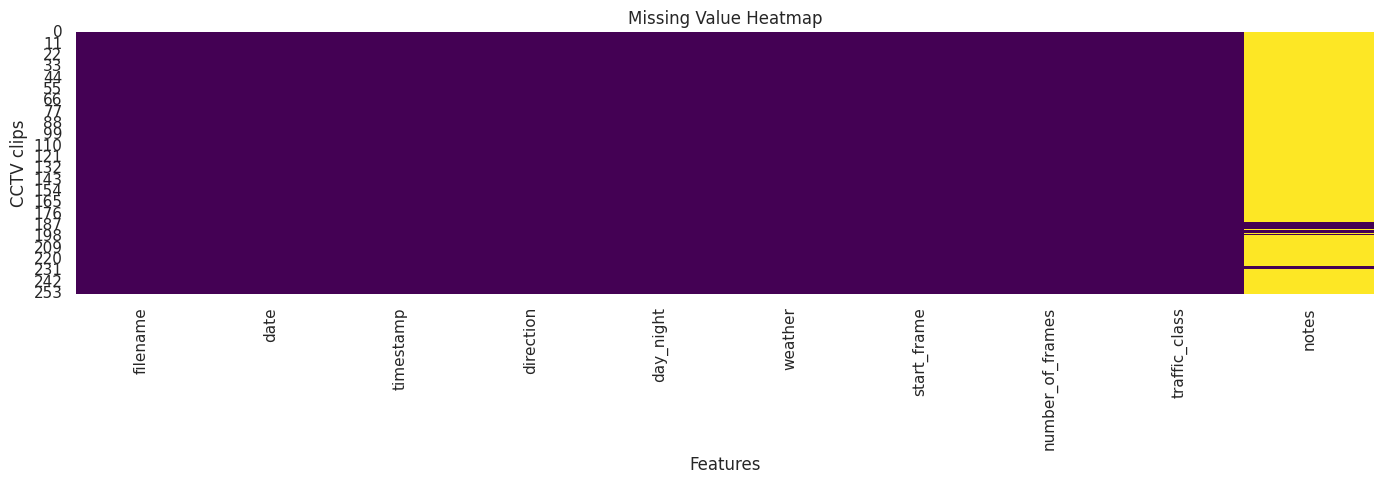

In [7]:
missing_counts = df.isnull().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage": (missing_counts / len(df) * 100).round(2)
})
display(missing_table)

plt.figure(figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap")
plt.xlabel("Features")
plt.ylabel("CCTV clips")
plt.tight_layout()
plt.show()

## 3. Traffic-class distribution

`traffic_class` is the available label in the metadata (for example, light, medium, and heavy). The plots show how the labelled clips are distributed.

Traffic class counts:


,count
traffic_class,
light,165
medium,45
heavy,44


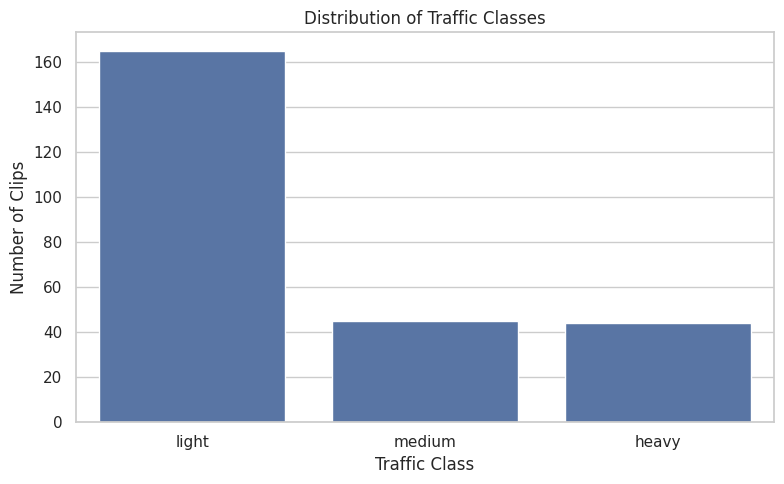

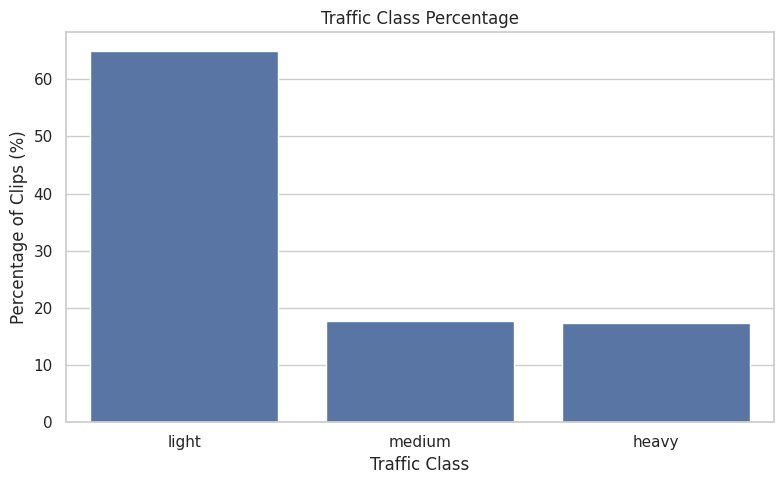

In [8]:
target_col = "traffic_class"

print("Traffic class counts:")
display(df[target_col].value_counts(dropna=False).rename_axis(target_col).to_frame("count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=target_col, order=df[target_col].value_counts().index)
plt.title("Distribution of Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Clips")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
class_percent = df[target_col].value_counts(normalize=True, dropna=False).mul(100)
sns.barplot(x=class_percent.index.astype(str), y=class_percent.values)
plt.title("Traffic Class Percentage")
plt.xlabel("Traffic Class")
plt.ylabel("Percentage of Clips (%)")
plt.tight_layout()
plt.show()

## 4. Distribution of numerical features

Histograms help show the distributions of timestamp, starting frame, and frame count. The date is kept as a date field and is summarized separately below.

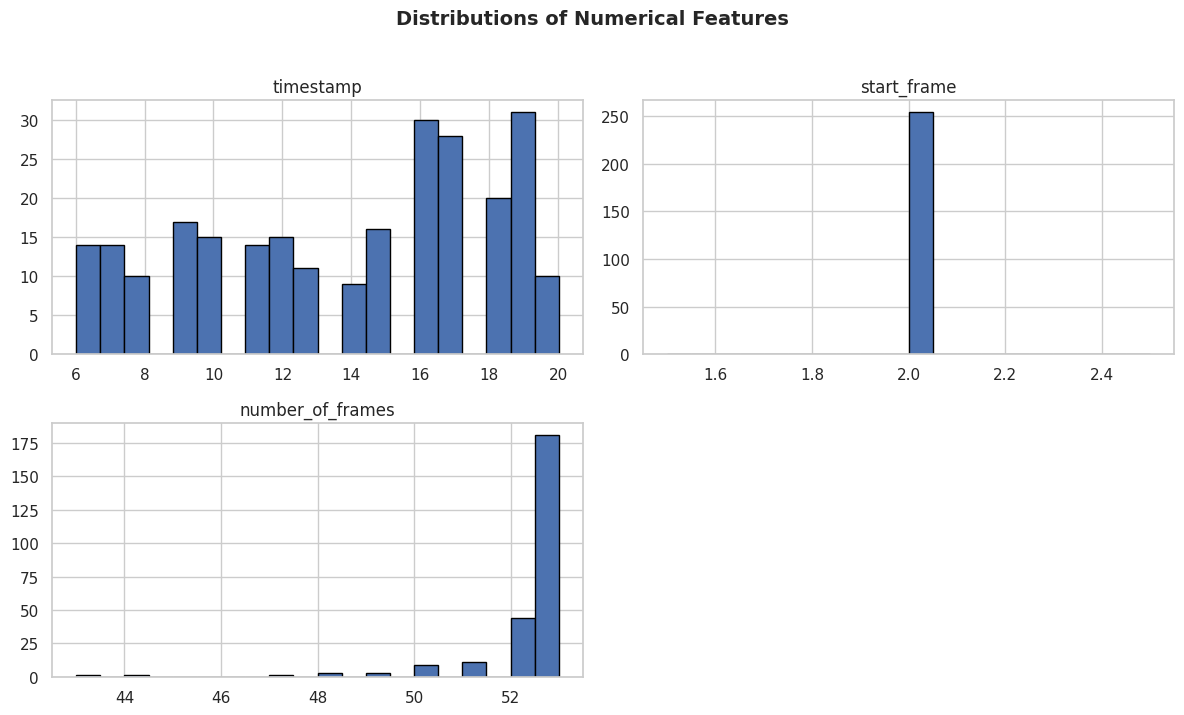

In [9]:
numeric_to_plot = [c for c in ["timestamp", "start_frame", "number_of_frames"] if c in df.columns]
if numeric_to_plot:
    df[numeric_to_plot].hist(bins=20, figsize=(12, 7), edgecolor="black")
    plt.suptitle("Distributions of Numerical Features", y=1.02, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical features available for histogram plotting.")

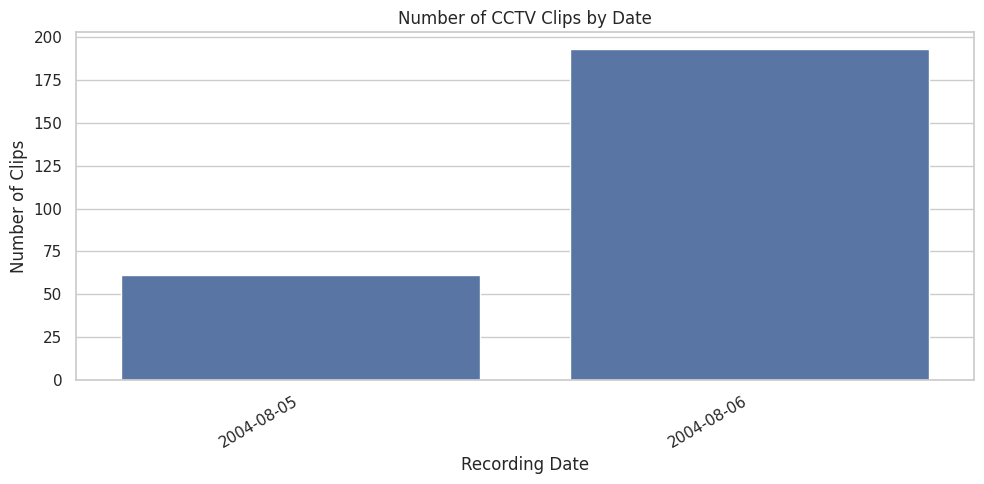

In [10]:
# Number of clips by recording date
date_counts = df["date"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
sns.barplot(x=date_counts.index.astype(str), y=date_counts.values)
plt.title("Number of CCTV Clips by Date")
plt.xlabel("Recording Date")
plt.ylabel("Number of Clips")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. Categorical feature analysis

These plots compare the clip counts by weather, day/night label, and direction. If a column has many categories, only its most common categories are displayed.

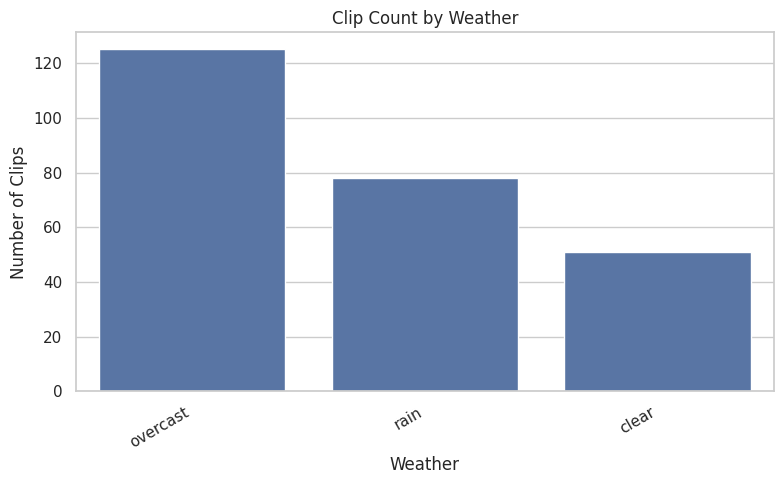

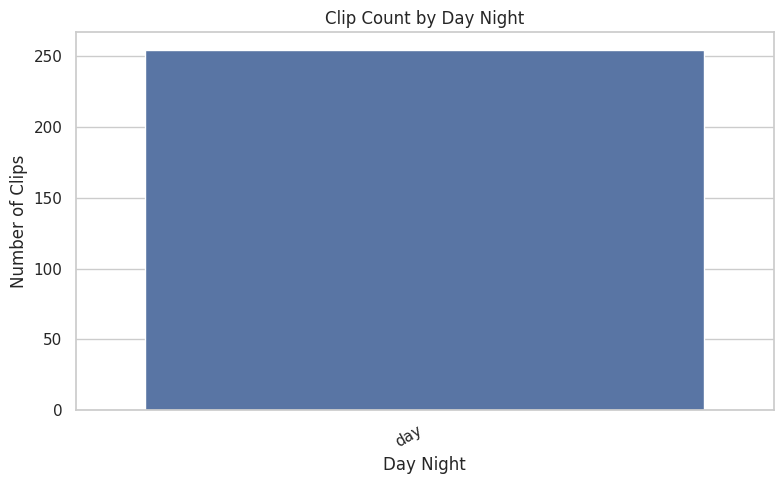

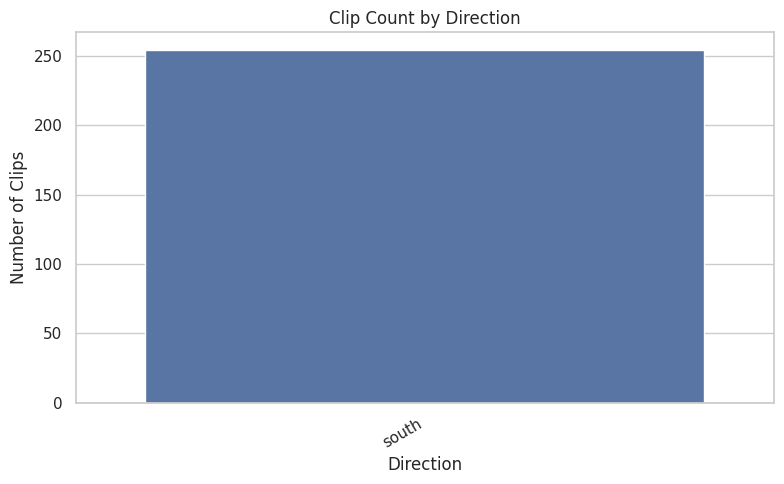

In [11]:
categorical_to_plot = ["weather", "day_night", "direction"]
for col in categorical_to_plot:
    if col in df.columns and df[col].notna().any():
        plt.figure(figsize=(8, 5))
        order = df[col].value_counts().head(15).index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Clip Count by {col.replace('_', ' ').title()}")
        plt.xlabel(col.replace("_", " ").title())
        plt.ylabel("Number of Clips")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

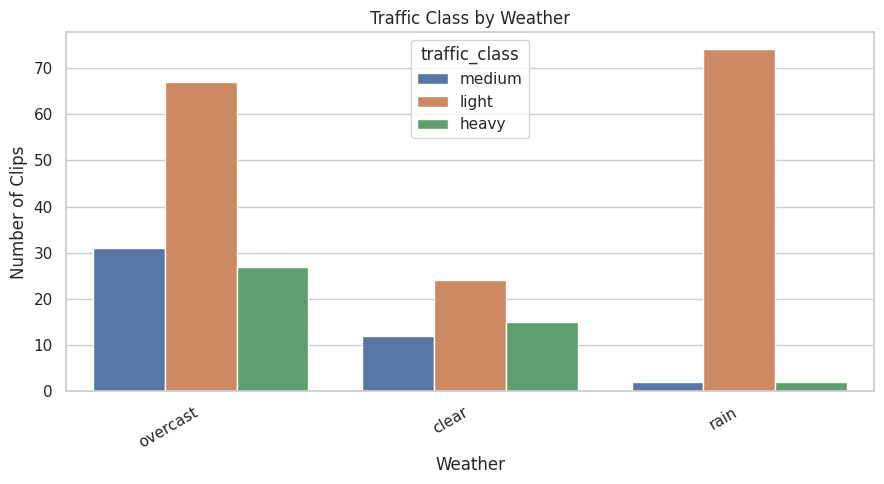

In [12]:
# Traffic class under different weather conditions
if {"weather", "traffic_class"}.issubset(df.columns):
    plt.figure(figsize=(9, 5))
    sns.countplot(data=df, x="weather", hue="traffic_class")
    plt.title("Traffic Class by Weather")
    plt.xlabel("Weather")
    plt.ylabel("Number of Clips")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Correlation heatmap

Correlation is calculated only for numerical columns. Identifier-like fields should not automatically be treated as meaningful predictors just because they are numeric.

--- Correlation Matrix ---


,timestamp,start_frame,number_of_frames
timestamp,1.000000,NaN,0.006748
start_frame,NaN,NaN,NaN
number_of_frames,0.006748,NaN,1.000000


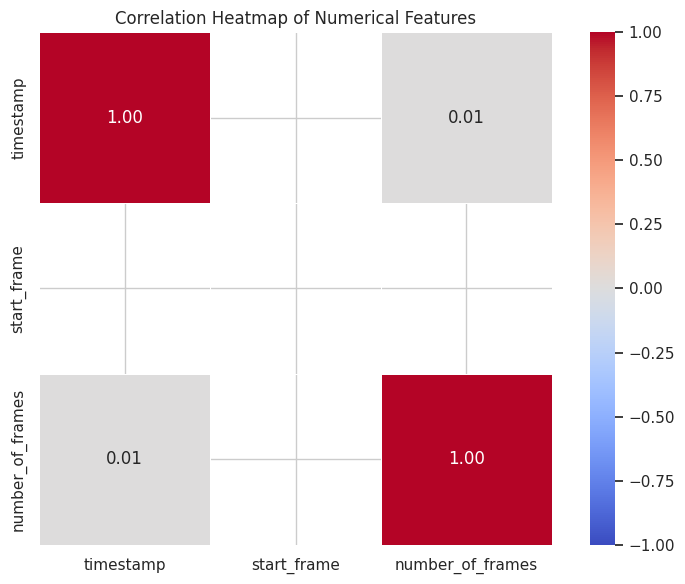

In [13]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    corr_matrix = numeric_df.corr()
    print("--- Correlation Matrix ---")
    display(corr_matrix)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
        vmin=-1, vmax=1, square=True, linewidths=0.5
    )
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required for a correlation heatmap.")

## 7. Boxplots and possible outliers

Boxplots help identify unusually high or low numerical values. Outliers should be checked against the dataset context before deciding whether to remove them.

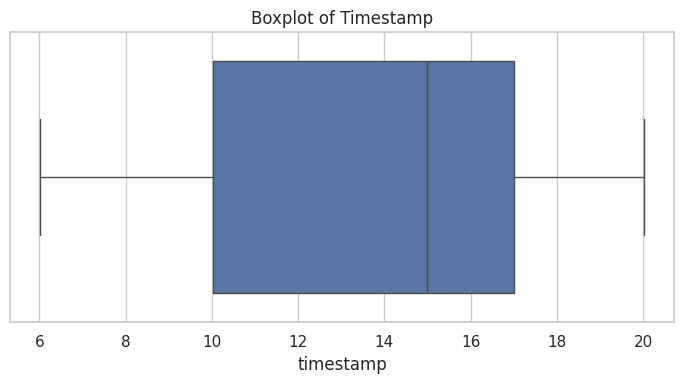

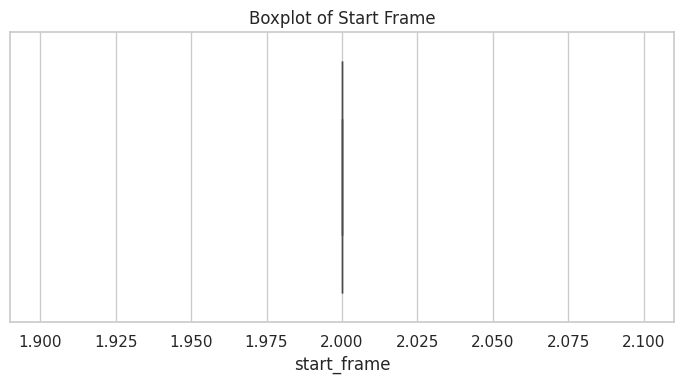

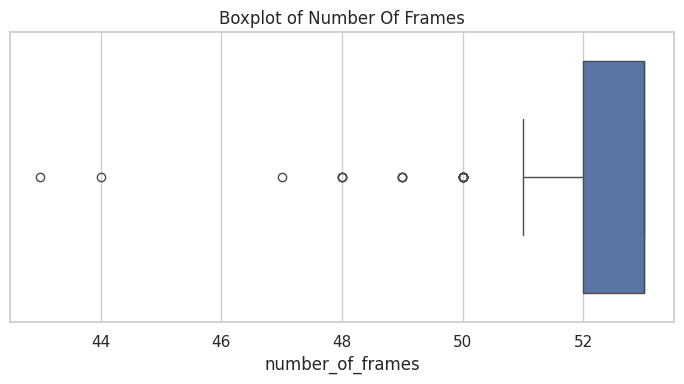

In [14]:
for col in numeric_to_plot:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=col)
    plt.title(f"Boxplot of {col.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

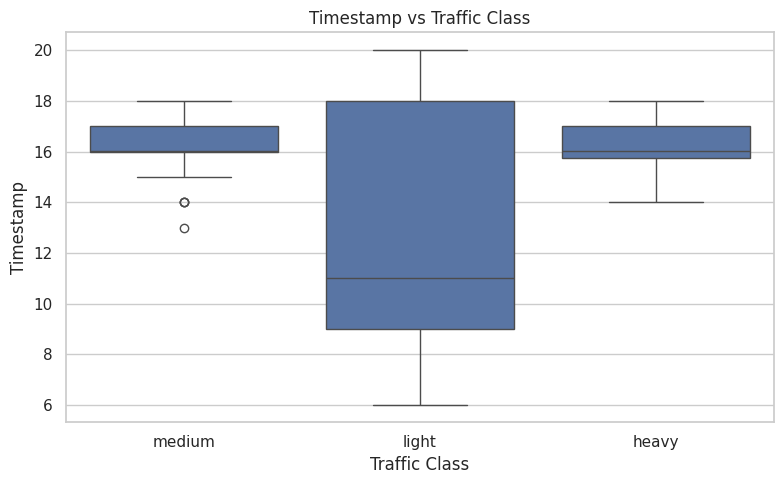

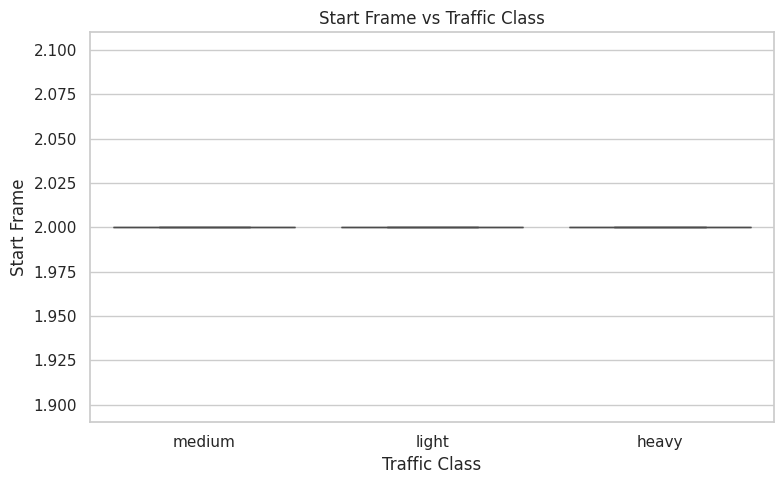

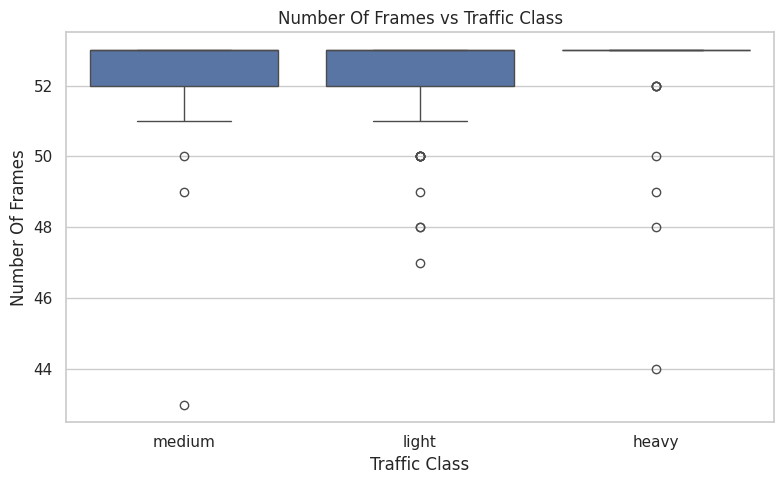

In [15]:
# Numerical features compared with the traffic class
for col in numeric_to_plot:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="traffic_class", y=col)
    plt.title(f"{col.replace('_', ' ').title()} vs Traffic Class")
    plt.xlabel("Traffic Class")
    plt.ylabel(col.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

## 8. Summary tables

The following tables summarize traffic labels and selected metadata fields for easy reference in the project report.

In [16]:
print("--- Traffic Class Summary ---")
display(
    df.groupby("traffic_class", dropna=False)
      .agg(
          clip_count=("filename", "count"),
          average_frames=("number_of_frames", "mean"),
          minimum_frames=("number_of_frames", "min"),
          maximum_frames=("number_of_frames", "max")
      )
      .round(2)
      .sort_values("clip_count", ascending=False)
)

print("--- Weather vs Traffic Class ---")
display(pd.crosstab(df["weather"], df["traffic_class"], margins=True))

--- Traffic Class Summary ---


,clip_count,average_frames,minimum_frames,maximum_frames
traffic_class,,,,
light,165,52.45,47,53
medium,45,52.36,43,53
heavy,44,52.43,44,53


--- Weather vs Traffic Class ---


traffic_class,heavy,light,medium,All
weather,,,,
clear,15,24,12,51
overcast,27,67,31,125
rain,2,74,2,78
All,44,165,45,254


## 9. EDA observations

Use the printed tables and plots above to write final observations. The following code generates data-driven points from this particular metadata file so that the notebook does not assume a distribution before examining the data.

In [17]:
print(f"1. The metadata contains {len(df)} CCTV clip records and {df.shape[1]} columns.")

print("\n2. Traffic class distribution:")
class_counts = df["traffic_class"].value_counts(dropna=False)
for label, count in class_counts.items():
    percentage = count / len(df) * 100 if len(df) else 0
    print(f"   - {label}: {count} clips ({percentage:.2f}%)")

print("\n3. Missing values:")
cols_with_missing = df.isnull().sum()
cols_with_missing = cols_with_missing[cols_with_missing > 0]
if cols_with_missing.empty:
    print("   - No missing values were found in the loaded metadata.")
else:
    for col, count in cols_with_missing.items():
        print(f"   - {col}: {count} missing values")

if "weather" in df.columns:
    print("\n4. Weather categories:")
    print(df["weather"].value_counts(dropna=False).to_string())

if "number_of_frames" in df.columns:
    print("\n5. Number of frames:")
    print(df["number_of_frames"].describe().round(2).to_string())

print("\n6. Scope note:")
print("   This EDA describes the supplied TrafficDB metadata and its traffic labels.")
print("   It does not measure YOLO detection precision/recall or validate RoadPulse AI's")
print("   provisional traffic-density thresholds. Those require labelled model-evaluation data.")

1. The metadata contains 254 CCTV clip records and 10 columns.

2. Traffic class distribution:
   - light: 165 clips (64.96%)
   - medium: 45 clips (17.72%)
   - heavy: 44 clips (17.32%)

3. Missing values:
   - notes: 240 missing values

4. Weather categories:
weather
overcast    125
rain         78
clear        51

5. Number of frames:
count    254.00
mean      52.43
std        1.30
min       43.00
25%       52.00
50%       53.00
75%       53.00
max       53.00

6. Scope note:
   This EDA describes the supplied TrafficDB metadata and its traffic labels.
   It does not measure YOLO detection precision/recall or validate RoadPulse AI's
   provisional traffic-density thresholds. Those require labelled model-evaluation data.


## Conclusion

The EDA examines the TrafficDB metadata associated with RoadPulse AI: data structure, missing values, traffic-class balance, numerical distributions, categorical distributions, correlations, and possible outliers.

**Important limitation:** RoadPulse AI currently uses a pretrained YOLOv8 detector and ByteTrack to analyze an uploaded video. This metadata EDA is exploratory analysis of the historical clip labels; it is not proof of model accuracy and does not mean the YOLO detector was trained on this dataset.